In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import roc_curve, auc, roc_auc_score

from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold

# Grafici
import matplotlib.pyplot as plt
import seaborn as sns

# Keras
import tensorflow as tf
from scikeras.wrappers import KerasClassifier
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.regularizers import l2, l1
from keras.layers import Dropout
from sklearn.model_selection import RandomizedSearchCV
from keras.callbacks import EarlyStopping, ModelCheckpoint
from keras.models import load_model

# Optuna per l'ottimizzazione
import optuna
from optuna.samplers import TPESampler

# explainability
import shap
import lime
import lime.lime_tabular

In [2]:
####
# DATASET
####
df = pd.read_parquet("df_pulito.parquet")
# df["bmi"] = (df["Physical-Weight"] / (df["Physical-Height"] ** 2)) * 703

colonne_stagioni = [
    "Basic_Demos-Enroll_Season",
    "BIA-Season",
    "CGAS-Season",
    "FGC-Season",
    "Fitness_Endurance-Season",
    "PCIAT-Season",
    "Physical-Season",
    "PreInt_EduHx-Season",
    "SDS-Season"
]

df = df.drop(columns=colonne_stagioni)

# Train Test sii
pciat_cols = [f"PCIAT-PCIAT_{i:02d}" for i in range(1, 21)]
X = df.drop(columns=["sii", "risultati",
            "PCIAT-PCIAT_Total", "id"] + pciat_cols)
y = df["sii"]  # per valutare sii, praticamente classificazione
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=222)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
# per il training
class_weight_dict = dict(enumerate(class_weights))

cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=222)

# VALUTAZIONE sii
---

In [18]:
######
# MODELLO NO REGULARIZATION
######

# serve perchè numpy fa le bizze
if hasattr(y_train, 'to_numpy'):
    y_train_np = y_train.to_numpy()
else:
    y_train_np = y_train


def objective_noreg(trial):
    """
    Funzione obiettivo eseguita da Optuna per ogni singolo trial.
    Costruisce, addestra e valuta una configurazione usando la Cross-Validation.
    """
    # Iperparametri
    n_layers = trial.suggest_int('n_layers', 1, 8)
    activation = trial.suggest_categorical(
        'activation', ['relu', 'elu', 'swish'])
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-1, log=True)
    batch_size = trial.suggest_categorical(
        'batch_size', [512, 1024, 2048, 4096])

    units_per_layer = [trial.suggest_categorical(
        f'n_units_l{i}', [32, 64, 128, 256, 512, 1024, 2048]) for i in range(n_layers)]

    fold_scores = []

    # Loop di Cross-Validation
    for train_idx, val_idx in cv_stratified.split(X_train_scaled, y_train_np):
        X_tr, X_val = X_train_scaled[train_idx], X_train_scaled[val_idx]
        y_tr, y_val = y_train_np[train_idx], y_train_np[val_idx]

        # Costruzione Modello Keras
        model = Sequential()
        model.add(keras.layers.Input(shape=(X_train_scaled.shape[1],)))

        for units in units_per_layer:
            model.add(Dense(units, activation=activation))

        model.add(Dense(4, activation='softmax'))

        # Ottimizzatore e compile
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
        model.compile(
            loss='sparse_categorical_crossentropy',
            optimizer=optimizer
        )

        # Early Stopping
        es = keras.callbacks.EarlyStopping(
            monitor='val_loss',
            min_delta=0,
            patience=20,
            verbose=0,
            restore_best_weights=True
        )

        # Addestramento sul fold
        model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=500,
            batch_size=batch_size,
            callbacks=[es],
            class_weight=class_weight_dict,
            verbose=0
        )

        # Valutazione
        y_pred_prob = model.predict(X_val, verbose=0)
        y_pred = np.argmax(y_pred_prob, axis=1)

        score = f1_score(y_val, y_pred, average='macro')
        fold_scores.append(score)

    return np.mean(fold_scores)


# Esecuzione
if __name__ == "__main__":

    storage_name = "sqlite:///optuna_dnn_tuning_noreg.db"

    study_noreg = optuna.create_study(
        direction="maximize",
        storage=storage_name,
        study_name="dnn_tuning_1",
        load_if_exists=True,
        sampler=TPESampler(seed=222)
    )

    study_noreg.optimize(objective_noreg, n_trials=30, n_jobs=1)

    print("\n### CONFIGURAZIONE OTTIMALE ###")
    for key, value in study_noreg.best_trial.params.items():
        print(f" - {key}: {value}")
    print(
        f"\nMiglior F1-Macro Medio (Cross-Validation): {study_noreg.best_value:.4f}")

    # Salvataggio modello
    best_param_noreg = study_noreg.best_params

    final_model_noreg = Sequential()
    final_model_noreg.add(keras.layers.Input(shape=(X_train_scaled.shape[1],)))

    for i in range(best_param_noreg['n_layers']):
        units = best_param_noreg[f'n_units_l{i}']
        final_model_noreg.add(
            Dense(units, activation=best_param_noreg['activation']))

    final_model_noreg.add(Dense(4, activation='softmax'))

    optimizer_final_noreg = keras.optimizers.Adam(
        learning_rate=best_param_noreg['learning_rate'])
    final_model_noreg.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=optimizer_final_noreg,
        metrics=['accuracy']
    )

    es_final = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        min_delta=0,
        patience=20,
        verbose=1,
        restore_best_weights=True
    )

    final_model_noreg.fit(
        X_train_scaled, y_train_np,
        validation_split=0.1,
        epochs=500,
        batch_size=best_param_noreg['batch_size'],
        callbacks=[es_final],
        class_weight=class_weight_dict,
        verbose=0
    )

    # Salvataggio modello
    final_model_noreg.save('best_model_NOREG.keras')
    print("Modello salvato con successo come 'best_model_NOREG.keras'")

    # Valutazione su test
    print("\n### REPORT DI CLASSIFICAZIONE SUL TEST SET ###")
    y_pred_prob = final_model_noreg.predict(X_test_scaled, verbose=0)
    y_pred = np.argmax(y_pred_prob, axis=1)

    print(classification_report(y_test, y_pred))

[I 2026-06-25 12:50:02,411] A new study created in RDB with name: dnn_tuning_1
[I 2026-06-25 12:50:21,234] Trial 0 finished with value: 0.30724058485556005 and parameters: {'n_layers': 5, 'activation': 'elu', 'learning_rate': 0.0001291415114015285, 'batch_size': 1024, 'n_units_l0': 2048, 'n_units_l1': 128, 'n_units_l2': 2048, 'n_units_l3': 32, 'n_units_l4': 32}. Best is trial 0 with value: 0.30724058485556005.
[I 2026-06-25 12:50:33,397] Trial 1 finished with value: 0.22326382426983873 and parameters: {'n_layers': 8, 'activation': 'relu', 'learning_rate': 0.004557965951597541, 'batch_size': 1024, 'n_units_l0': 2048, 'n_units_l1': 2048, 'n_units_l2': 512, 'n_units_l3': 64, 'n_units_l4': 128, 'n_units_l5': 1024, 'n_units_l6': 512, 'n_units_l7': 128}. Best is trial 0 with value: 0.30724058485556005.
[I 2026-06-25 12:50:50,336] Trial 2 finished with value: 0.23433322584821253 and parameters: {'n_layers': 5, 'activation': 'elu', 'learning_rate': 0.015159348035210234, 'batch_size': 1024, 'n_


### CONFIGURAZIONE OTTIMALE ###
 - n_layers: 7
 - activation: relu
 - learning_rate: 0.0002483515885043313
 - batch_size: 2048
 - n_units_l0: 128
 - n_units_l1: 1024
 - n_units_l2: 64
 - n_units_l3: 2048
 - n_units_l4: 1024
 - n_units_l5: 2048
 - n_units_l6: 64

Miglior F1-Macro Medio (Cross-Validation): 0.3341
Restoring model weights from the end of the best epoch: 34.
Epoch 54: early stopping
Modello salvato con successo come 'best_model_NOREG.keras'

### REPORT DI CLASSIFICAZIONE SUL TEST SET ###
              precision    recall  f1-score   support

           0       0.77      0.71      0.74      1689
           1       0.27      0.35      0.31       469
           2       0.26      0.24      0.25       284
           3       0.03      0.08      0.05        26

    accuracy                           0.58      2468
   macro avg       0.33      0.34      0.33      2468
weighted avg       0.61      0.58      0.59      2468



In [19]:
######
# MODELLO L1 LASSO
######

if hasattr(y_train, 'to_numpy'):
    y_train_np = y_train.to_numpy()
else:
    y_train_np = y_train


def objective_l1(trial):
    """
    Funzione obiettivo eseguita da Optuna per ogni singolo trial.
    Costruisce, addestra e valuta una configurazione usando la Cross-Validation e la regolarizzazione L1.
    """
    # Iperparametri
    n_layers = trial.suggest_int('n_layers', 1, 8)
    activation = trial.suggest_categorical(
        'activation', ['relu', 'elu', 'swish'])
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-1, log=True)
    batch_size = trial.suggest_categorical(
        'batch_size', [512, 1024, 2048, 4096])
    l1_lambda = trial.suggest_float('l1_lambda', 1e-5, 1e-2, log=True)

    units_per_layer = [trial.suggest_categorical(
        f'n_units_l{i}', [32, 64, 128, 256, 512, 1024, 2048]) for i in range(n_layers)]

    fold_scores = []

    # Loop di Cross-Validation
    for train_idx, val_idx in cv_stratified.split(X_train_scaled, y_train_np):
        X_tr, X_val = X_train_scaled[train_idx], X_train_scaled[val_idx]
        y_tr, y_val = y_train_np[train_idx], y_train_np[val_idx]

        # Costruzione Modello Keras
        model = Sequential()
        model.add(keras.layers.Input(shape=(X_train_scaled.shape[1],)))

        for units in units_per_layer:
            model.add(Dense(
                units,
                activation=activation,
                kernel_regularizer=keras.regularizers.l1(l1_lambda)
            ))

        model.add(Dense(4, activation='softmax'))

        # Compilazione
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
        model.compile(
            loss='sparse_categorical_crossentropy',
            optimizer=optimizer
        )

        # Early Stopping
        es = keras.callbacks.EarlyStopping(
            monitor='val_loss',
            min_delta=0,
            patience=20,
            verbose=0,
            restore_best_weights=True
        )

        # Addestramento
        model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=500,
            batch_size=batch_size,
            callbacks=[es],
            class_weight=class_weight_dict,
            verbose=0
        )

        # Valutazione sul fold di validazione
        y_pred_prob = model.predict(X_val, verbose=0)
        y_pred = np.argmax(y_pred_prob, axis=1)

        score = f1_score(y_val, y_pred, average='macro')
        fold_scores.append(score)

    return np.mean(fold_scores)


# Processo
if __name__ == "__main__":

    storage_name = "sqlite:///optuna_dnn_tuning_l1.db"

    study_l1 = optuna.create_study(
        direction="maximize",
        storage=storage_name,
        study_name="dnn_l1_tuning_1",
        load_if_exists=True,
        sampler=TPESampler(seed=222)
    )

    study_l1.optimize(objective_l1, n_trials=30, n_jobs=1)

    print("\n### CONFIGURAZIONE OTTIMALE ###")
    for key, value in study_l1.best_trial.params.items():
        print(f" - {key}: {value}")
    print(
        f"\nMiglior F1-Macro Medio (Cross-Validation L1): {study_l1.best_value:.4f}")

    # Addestramento e Salvataggio
    best_param_l1 = study_l1.best_params

    final_model_l1 = Sequential()
    final_model_l1.add(keras.layers.Input(shape=(X_train_scaled.shape[1],)))

    for i in range(best_param_l1['n_layers']):
        units = best_param_l1[f'n_units_l{i}']
        final_model_l1.add(Dense(
            units,
            activation=best_param_l1['activation'],
            kernel_regularizer=keras.regularizers.l1(
                best_param_l1['l1_lambda'])
        ))

    final_model_l1.add(Dense(4, activation='softmax'))

    # Compilazione
    optimizer_final_l1 = keras.optimizers.Adam(
        learning_rate=best_param_l1['learning_rate'])
    final_model_l1.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=optimizer_final_l1,
        metrics=['accuracy']
    )

    # Early Stopping
    es_final = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        min_delta=0,
        patience=20,
        verbose=1,
        restore_best_weights=True
    )

    # Addestramento finale
    final_model_l1.fit(
        X_train_scaled, y_train_np,
        validation_split=0.1,
        epochs=500,
        batch_size=best_param_l1['batch_size'],
        callbacks=[es_final],
        class_weight=class_weight_dict,
        verbose=0
    )

    # Salvataggio effettivo
    final_model_l1.save('best_model_L1.keras')

    # Valutazione su Test
    y_pred_prob = final_model_l1.predict(X_test_scaled, verbose=0)
    y_pred = np.argmax(y_pred_prob, axis=1)

    print(classification_report(y_test, y_pred))

[I 2026-06-25 12:55:56,569] A new study created in RDB with name: dnn_l1_tuning_1
[I 2026-06-25 12:57:23,007] Trial 0 finished with value: 0.3058678231459099 and parameters: {'n_layers': 5, 'activation': 'elu', 'learning_rate': 0.0001291415114015285, 'batch_size': 1024, 'l1_lambda': 7.285701681802387e-05, 'n_units_l0': 1024, 'n_units_l1': 64, 'n_units_l2': 2048, 'n_units_l3': 2048, 'n_units_l4': 2048}. Best is trial 0 with value: 0.3058678231459099.
[I 2026-06-25 12:57:42,454] Trial 1 finished with value: 0.14848840768969285 and parameters: {'n_layers': 8, 'activation': 'swish', 'learning_rate': 0.004499862776019602, 'batch_size': 512, 'l1_lambda': 0.00014551819467846668, 'n_units_l0': 512, 'n_units_l1': 512, 'n_units_l2': 2048, 'n_units_l3': 128, 'n_units_l4': 32, 'n_units_l5': 256, 'n_units_l6': 128, 'n_units_l7': 32}. Best is trial 0 with value: 0.3058678231459099.
[I 2026-06-25 12:58:37,015] Trial 2 finished with value: 0.23407354567465627 and parameters: {'n_layers': 6, 'activatio


### CONFIGURAZIONE OTTIMALE ###
 - n_layers: 6
 - activation: relu
 - learning_rate: 0.0002675609800062442
 - batch_size: 2048
 - l1_lambda: 2.7795892145780453e-05
 - n_units_l0: 64
 - n_units_l1: 1024
 - n_units_l2: 64
 - n_units_l3: 32
 - n_units_l4: 1024
 - n_units_l5: 32

Miglior F1-Macro Medio (Cross-Validation L1): 0.3319
Restoring model weights from the end of the best epoch: 66.
Epoch 86: early stopping
              precision    recall  f1-score   support

           0       0.78      0.64      0.70      1689
           1       0.27      0.40      0.32       469
           2       0.23      0.26      0.25       284
           3       0.04      0.12      0.06        26

    accuracy                           0.54      2468
   macro avg       0.33      0.35      0.33      2468
weighted avg       0.61      0.54      0.57      2468



In [20]:
######
# MODELLO L2 RIDGE
######

if hasattr(y_train, 'to_numpy'):
    y_train_np = y_train.to_numpy()
else:
    y_train_np = y_train


def objective_l2(trial):
    """
    Funzione obiettivo eseguita da Optuna per ogni singolo trial.
    Costruisce, addestra e valuta una configurazione usando la Cross-Validation e la regolarizzazione L2.
    """
    # Iperparametri
    n_layers = trial.suggest_int('n_layers', 1, 8)
    activation = trial.suggest_categorical(
        'activation', ['relu', 'elu', 'swish'])
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-1, log=True)
    batch_size = trial.suggest_categorical(
        'batch_size', [512, 1024, 2048, 4096])
    l2_lambda = trial.suggest_float('l2_lambda', 1e-5, 1e-2, log=True)

    units_per_layer = [trial.suggest_categorical(
        f'n_units_l{i}', [32, 64, 128, 256, 512, 1024, 2048]) for i in range(n_layers)]

    fold_scores = []

    # Loop di Cross-Validation
    for train_idx, val_idx in cv_stratified.split(X_train_scaled, y_train_np):
        X_tr, X_val = X_train_scaled[train_idx], X_train_scaled[val_idx]
        y_tr, y_val = y_train_np[train_idx], y_train_np[val_idx]

        # Costruzione Modello Keras
        model = Sequential()
        model.add(keras.layers.Input(shape=(X_train_scaled.shape[1],)))

        for units in units_per_layer:
            model.add(Dense(
                units,
                activation=activation,
                kernel_regularizer=keras.regularizers.l2(l2_lambda)
            ))

        model.add(Dense(4, activation='softmax'))

        # Compilazione
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
        model.compile(
            loss='sparse_categorical_crossentropy',
            optimizer=optimizer
        )

        # Early Stopping
        es = keras.callbacks.EarlyStopping(
            monitor='val_loss',
            min_delta=0,
            patience=20,
            verbose=0,
            restore_best_weights=True
        )

        # Addestramento
        model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=500,
            batch_size=batch_size,
            callbacks=[es],
            class_weight=class_weight_dict,
            verbose=0
        )

        # Valutazione
        y_pred_prob = model.predict(X_val, verbose=0)
        y_pred = np.argmax(y_pred_prob, axis=1)

        score = f1_score(y_val, y_pred, average='macro')
        fold_scores.append(score)

    return np.mean(fold_scores)


# Processo
if __name__ == "__main__":

    storage_name = "sqlite:///optuna_dnn_tuning_l2.db"

    study_l2 = optuna.create_study(
        direction="maximize",
        storage=storage_name,
        study_name="dnn_l2_tuning_1",
        load_if_exists=True,
        sampler=TPESampler(seed=222)
    )

    study_l2.optimize(objective_l2, n_trials=30, n_jobs=1)

    print("\n### CONFIGURAZIONE OTTIMALE ###")
    for key, value in study_l2.best_trial.params.items():
        print(f" - {key}: {value}")
    print(
        f"\nMiglior F1-Macro Medio (Cross-Validation L2): {study_l2.best_value:.4f}")

    # Addestramento e Salvataggio
    best_param_l2 = study_l2.best_params
    final_model_l2 = Sequential()
    final_model_l2.add(keras.layers.Input(shape=(X_train_scaled.shape[1],)))

    for i in range(best_param_l2['n_layers']):
        units = best_param_l2[f'n_units_l{i}']
        final_model_l2.add(Dense(
            units,
            activation=best_param_l2['activation'],
            kernel_regularizer=keras.regularizers.l2(
                best_param_l2['l2_lambda'])
        ))

    final_model_l2.add(Dense(4, activation='softmax'))

    # Compilazione
    optimizer_final_l2 = keras.optimizers.Adam(
        learning_rate=best_param_l2['learning_rate'])
    final_model_l2.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=optimizer_final_l2,
        metrics=['accuracy']
    )

    es_final = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        min_delta=0,
        patience=20,
        verbose=1,
        restore_best_weights=True
    )

    # Addestramento finale
    final_model_l2.fit(
        X_train_scaled, y_train_np,
        validation_split=0.1,
        epochs=500,
        batch_size=best_param_l2['batch_size'],
        callbacks=[es_final],
        class_weight=class_weight_dict,
        verbose=0
    )

    # Salvataggio
    final_model_l2.save('best_model_L2.keras')

    y_pred_prob = final_model_l2.predict(X_test_scaled, verbose=0)
    y_pred = np.argmax(y_pred_prob, axis=1)

    print(classification_report(y_test, y_pred))

[I 2026-06-25 13:07:15,146] A new study created in RDB with name: dnn_l2_tuning_1
[I 2026-06-25 13:07:39,957] Trial 0 finished with value: 0.3134887622031033 and parameters: {'n_layers': 5, 'activation': 'elu', 'learning_rate': 0.0001291415114015285, 'batch_size': 1024, 'l2_lambda': 7.285701681802387e-05, 'n_units_l0': 1024, 'n_units_l1': 64, 'n_units_l2': 2048, 'n_units_l3': 2048, 'n_units_l4': 2048}. Best is trial 0 with value: 0.3134887622031033.
[I 2026-06-25 13:08:00,486] Trial 1 finished with value: 0.28681577680116344 and parameters: {'n_layers': 8, 'activation': 'swish', 'learning_rate': 0.004499862776019602, 'batch_size': 512, 'l2_lambda': 0.00014551819467846668, 'n_units_l0': 512, 'n_units_l1': 512, 'n_units_l2': 2048, 'n_units_l3': 128, 'n_units_l4': 32, 'n_units_l5': 256, 'n_units_l6': 128, 'n_units_l7': 32}. Best is trial 0 with value: 0.3134887622031033.
[I 2026-06-25 13:08:53,544] Trial 2 finished with value: 0.26574891781658544 and parameters: {'n_layers': 6, 'activatio


### CONFIGURAZIONE OTTIMALE ###
 - n_layers: 4
 - activation: relu
 - learning_rate: 0.000805859067109091
 - batch_size: 2048
 - l2_lambda: 4.8355285625831926e-05
 - n_units_l0: 64
 - n_units_l1: 1024
 - n_units_l2: 128
 - n_units_l3: 1024

Miglior F1-Macro Medio (Cross-Validation L2): 0.3319
Restoring model weights from the end of the best epoch: 32.
Epoch 52: early stopping
              precision    recall  f1-score   support

           0       0.74      0.76      0.75      1689
           1       0.24      0.17      0.20       469
           2       0.26      0.28      0.27       284
           3       0.04      0.15      0.07        26

    accuracy                           0.59      2468
   macro avg       0.32      0.34      0.32      2468
weighted avg       0.58      0.59      0.58      2468



In [21]:
######
# MODELLO DROPOUT
######

if hasattr(y_train, 'to_numpy'):
    y_train_np = y_train.to_numpy()
else:
    y_train_np = y_train


def objective_drop(trial):
    """
    Funzione obiettivo eseguita da Optuna per ogni singolo trial.
    Costruisce, addestra e valuta una configurazione usando la Cross-Validation e il Dropout.
    """
    # Iperparametri
    n_layers = trial.suggest_int('n_layers', 1, 8)
    activation = trial.suggest_categorical(
        'activation', ['relu', 'elu', 'swish'])
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-1, log=True)
    batch_size = trial.suggest_categorical(
        'batch_size', [512, 1024, 2048, 4096])
    dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5, step=0.05)

    units_per_layer = [trial.suggest_categorical(
        f'n_units_l{i}', [32, 64, 128, 256, 512, 1024, 2048]) for i in range(n_layers)]

    fold_scores = []

    # Loop di Cross-Validation
    for train_idx, val_idx in cv_stratified.split(X_train_scaled, y_train_np):
        X_tr, X_val = X_train_scaled[train_idx], X_train_scaled[val_idx]
        y_tr, y_val = y_train_np[train_idx], y_train_np[val_idx]

        # Costruzione Modello Keras
        model = Sequential()
        model.add(keras.layers.Input(shape=(X_train_scaled.shape[1],)))

        for units in units_per_layer:
            model.add(Dense(units, activation=activation))
            model.add(Dropout(dropout_rate))

        model.add(Dense(4, activation='softmax'))

        # Compilazione
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
        model.compile(
            loss='sparse_categorical_crossentropy',
            optimizer=optimizer
        )

        # Early Stopping
        es = keras.callbacks.EarlyStopping(
            monitor='val_loss',
            min_delta=0,
            patience=20,
            verbose=0,
            restore_best_weights=True
        )

        # Addestramento sul fold
        model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=500,
            batch_size=batch_size,
            callbacks=[es],
            class_weight=class_weight_dict,
            verbose=0
        )

        # Valutazione sul fold di validazione
        y_pred_prob = model.predict(X_val, verbose=0)
        y_pred = np.argmax(y_pred_prob, axis=1)

        score = f1_score(y_val, y_pred, average='macro')
        fold_scores.append(score)

    return np.mean(fold_scores)


# Processo
if __name__ == "__main__":

    storage_name = "sqlite:///optuna_dnn_tuning_dropout.db"

    study_dropout = optuna.create_study(
        direction="maximize",
        storage=storage_name,
        study_name="dnn_dropout_tuning_1",
        load_if_exists=True,
        sampler=TPESampler(seed=222)
    )

    study_dropout.optimize(objective_drop, n_trials=30, n_jobs=1)

    print("\n### CONFIGURAZIONE OTTIMALE ###")
    for key, value in study_dropout.best_trial.params.items():
        print(f" - {key}: {value}")
    print(
        f"\nMiglior F1-Macro Medio (Cross-Validation Dropout): {study_dropout.best_value:.4f}")

    # Addestramento e Salvataggio
    best_param_dropout = study_dropout.best_params

    final_model_dropout = Sequential()
    final_model_dropout.add(keras.layers.Input(
        shape=(X_train_scaled.shape[1],)))

    for i in range(best_param_dropout['n_layers']):
        units = best_param_dropout[f'n_units_l{i}']
        final_model_dropout.add(
            Dense(units, activation=best_param_dropout['activation']))
        final_model_dropout.add(Dropout(best_param_dropout['dropout_rate']))

    final_model_dropout.add(Dense(4, activation='softmax'))

    # Compilazione
    optimizer_final_drop = keras.optimizers.Adam(
        learning_rate=best_param_dropout['learning_rate'])
    final_model_dropout.compile(
        loss='sparse_categorical_crossentropy',
        optimizer=optimizer_final_drop,
        metrics=['accuracy']
    )

    # Early Stopping
    es_final = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        min_delta=0,
        patience=20,
        verbose=1,
        restore_best_weights=True
    )

    # Addestramento finale
    final_model_dropout.fit(
        X_train_scaled, y_train_np,
        validation_split=0.1,
        epochs=500,
        batch_size=best_param_dropout['batch_size'],
        callbacks=[es_final],
        class_weight=class_weight_dict,
        verbose=0
    )

    # Salvataggio
    final_model_dropout.save('best_model_DROPOUT.keras')

    # Valutazione su test
    y_pred_prob = final_model_dropout.predict(X_test_scaled, verbose=0)
    y_pred = np.argmax(y_pred_prob, axis=1)

    print(classification_report(y_test, y_pred))

[I 2026-06-25 13:14:08,154] A new study created in RDB with name: dnn_dropout_tuning_1
[I 2026-06-25 13:14:38,485] Trial 0 finished with value: 0.30372819153966735 and parameters: {'n_layers': 5, 'activation': 'elu', 'learning_rate': 0.0001291415114015285, 'batch_size': 1024, 'dropout_rate': 0.2, 'n_units_l0': 1024, 'n_units_l1': 64, 'n_units_l2': 2048, 'n_units_l3': 2048, 'n_units_l4': 2048}. Best is trial 0 with value: 0.30372819153966735.
[I 2026-06-25 13:14:58,995] Trial 1 finished with value: 0.24489686887430934 and parameters: {'n_layers': 8, 'activation': 'swish', 'learning_rate': 0.004499862776019602, 'batch_size': 512, 'dropout_rate': 0.25, 'n_units_l0': 512, 'n_units_l1': 512, 'n_units_l2': 2048, 'n_units_l3': 128, 'n_units_l4': 32, 'n_units_l5': 256, 'n_units_l6': 128, 'n_units_l7': 32}. Best is trial 0 with value: 0.30372819153966735.
[I 2026-06-25 13:15:09,918] Trial 2 finished with value: 0.17950396700973986 and parameters: {'n_layers': 6, 'activation': 'elu', 'learning_r


### CONFIGURAZIONE OTTIMALE ###
 - n_layers: 3
 - activation: relu
 - learning_rate: 0.0008762517291000013
 - batch_size: 2048
 - dropout_rate: 0.15000000000000002
 - n_units_l0: 2048
 - n_units_l1: 2048
 - n_units_l2: 64

Miglior F1-Macro Medio (Cross-Validation Dropout): 0.3365
Restoring model weights from the end of the best epoch: 31.
Epoch 51: early stopping
              precision    recall  f1-score   support

           0       0.77      0.73      0.75      1689
           1       0.27      0.33      0.30       469
           2       0.24      0.23      0.24       284
           3       0.06      0.08      0.07        26

    accuracy                           0.59      2468
   macro avg       0.34      0.34      0.34      2468
weighted avg       0.60      0.59      0.59      2468



In [4]:
####
# COMPARISON MODELLI
####

# Caricamento modelli migliori
best_NOREG_model = load_model('best_model_NOREG.keras')
best_L1_model = load_model('best_model_L1.keras')
best_L2_model = load_model('best_model_L2.keras')
best_DROPOUT_model = load_model('best_model_DROPOUT.keras')

modelli = {
    "NOREG": best_NOREG_model,
    "L1": best_L1_model,
    "L2": best_L2_model,
    "DROPOUT": best_DROPOUT_model
}

for nome, modello in modelli.items():
    print(f"\n--- Modello: {nome} ---")
    print(f"Learning Rate: {modello.optimizer.learning_rate.numpy()}")

    for i, layer in enumerate(modello.layers):
        config = layer.get_config()
        if 'Dense' in layer.__class__.__name__:
            print(
                f"Layer {i} (Dense): {config['units']} neuroni, Attivazione: {config['activation']}")
            if config.get('kernel_regularizer'):
                reg_config = config['kernel_regularizer']['config']
                print(f"  Regolarizzazione: {reg_config}")
        elif 'Dropout' in layer.__class__.__name__:
            print(f"Layer {i} (Dropout): Rate = {config['rate']}")

# Valutazioni di Keras
loss_NOREG, acc_NOREG = best_NOREG_model.evaluate(
    X_test_scaled, y_test, verbose=0)
loss_L1, acc_L1 = best_L1_model.evaluate(X_test_scaled, y_test, verbose=0)
loss_L2, acc_L2 = best_L2_model.evaluate(X_test_scaled, y_test, verbose=0)
loss_DROPOUT, acc_DROPOUT = best_DROPOUT_model.evaluate(
    X_test_scaled, y_test, verbose=0)

# Predizioni
pred_NOREG = np.argmax(best_NOREG_model.predict(
    X_test_scaled, verbose=0), axis=1)
pred_L1 = np.argmax(best_L1_model.predict(X_test_scaled, verbose=0), axis=1)
pred_L2 = np.argmax(best_L2_model.predict(X_test_scaled, verbose=0), axis=1)
pred_DROPOUT = np.argmax(best_DROPOUT_model.predict(
    X_test_scaled, verbose=0), axis=1)

# Calcolo F1-Score Macro
f1_NOREG = f1_score(y_test, pred_NOREG, average='macro')
f1_L1 = f1_score(y_test, pred_L1, average='macro')
f1_L2 = f1_score(y_test, pred_L2, average='macro')
f1_DROPOUT = f1_score(y_test, pred_DROPOUT, average='macro')

# Stampa finale
print("### COMPARAZIONE FINALE MODELLI DNN ###\n")
print(f"{'Modello':<25} | {'Loss':<8} | {'Accuracy':<10} | {'F1-Macro':<10}")
print("-" * 65)
print(f"{'No Regolarizzazione':<25} | {loss_NOREG:<8.4f} | {acc_NOREG:<10.4f} | {f1_NOREG:<10.4f}")
print(f"{'L1 (Lasso)':<25} | {loss_L1:<8.4f} | {acc_L1:<10.4f} | {f1_L1:<10.4f}")
print(f"{'L2 (Ridge)':<25} | {loss_L2:<8.4f} | {acc_L2:<10.4f} | {f1_L2:<10.4f}")
print(f"{'Dropout':<25} | {loss_DROPOUT:<8.4f} | {acc_DROPOUT:<10.4f} | {f1_DROPOUT:<10.4f}")


--- Modello: NOREG ---
Learning Rate: 0.0002483516000211239
Layer 0 (Dense): 128 neuroni, Attivazione: relu
Layer 1 (Dense): 1024 neuroni, Attivazione: relu
Layer 2 (Dense): 64 neuroni, Attivazione: relu
Layer 3 (Dense): 2048 neuroni, Attivazione: relu
Layer 4 (Dense): 1024 neuroni, Attivazione: relu
Layer 5 (Dense): 2048 neuroni, Attivazione: relu
Layer 6 (Dense): 64 neuroni, Attivazione: relu
Layer 7 (Dense): 4 neuroni, Attivazione: softmax

--- Modello: L1 ---
Learning Rate: 0.0002675609721336514
Layer 0 (Dense): 64 neuroni, Attivazione: relu
  Regolarizzazione: {'l1': 2.7795891583082266e-05}
Layer 1 (Dense): 1024 neuroni, Attivazione: relu
  Regolarizzazione: {'l1': 2.7795891583082266e-05}
Layer 2 (Dense): 64 neuroni, Attivazione: relu
  Regolarizzazione: {'l1': 2.7795891583082266e-05}
Layer 3 (Dense): 32 neuroni, Attivazione: relu
  Regolarizzazione: {'l1': 2.7795891583082266e-05}
Layer 4 (Dense): 1024 neuroni, Attivazione: relu
  Regolarizzazione: {'l1': 2.7795891583082266e-05}


In [7]:
modelli_pred = {
    "NOREG": pred_NOREG,
    "L1": pred_L1,
    "L2": pred_L2,
    "DROPOUT": pred_DROPOUT
}

print("### GENERAZIONE TABELLA LATEX COMBINATA ###\n")

print("% Assicurati di inserire \\usepackage{multirow} nel preambolo")
print("\\begin{table}[H]")
print("\\centering")
print("\\small % Riduce la dimensione del font per renderla più compatta")
print("\\caption{Classification reports comparison for all DNN models.}")
print("\\label{tab:combined_dnn_report}")
# Aggiornato per riflettere 8 colonne (l + 7 c)
print("\\begin{tabular}{lccccccc}")
print("\\hline")
# Aggiunte le intestazioni per Accuracy e Macro F1
print("\\textbf{Model} & \\textbf{Class} & \\textbf{Precision} & \\textbf{Recall} & \\textbf{F1-score} & \\textbf{Support} & \\textbf{Accuracy} & \\textbf{Macro F1} \\\\ \\hline")

for nome, pred in modelli_pred.items():
    report = classification_report(y_test, pred, output_dict=True)

    # Estrazione delle metriche globali del modello
    acc = f"{report['accuracy']:.4f}"
    macro_f1 = f"{report['macro avg']['f1-score']:.4f}"

    # Estrae solo le chiavi relative alle classi (0, 1, 2, 3)
    classi = [k for k in report.keys() if k.isdigit()]
    n_classi = len(classi)

    for i, key in enumerate(classi):
        metrics = report[key]
        prec = f"{metrics['precision']:.2f}"
        rec = f"{metrics['recall']:.2f}"
        f1 = f"{metrics['f1-score']:.2f}"
        supp = int(metrics['support'])

        # Se è la prima riga del modello, inserisce il multirow per nome, accuracy e macro f1
        if i == 0:
            print(
                f"\\multirow{{{n_classi}}}{{*}}{{\\textbf{{{nome}}}}} & {key} & {prec} & {rec} & {f1} & {supp} & "
                f"\\multirow{{{n_classi}}}{{*}}{{{acc}}} & \\multirow{{{n_classi}}}{{*}}{{{macro_f1}}} \\\\"
            )
        # Per le righe successive, lascia vuota la prima colonna e le ultime due
        else:
            print(f" & {key} & {prec} & {rec} & {f1} & {supp} & & \\\\")

    # Riga di separazione tra i diversi modelli
    print("\\hline")

print("\\end{tabular}")
print("\\end{table}")

### GENERAZIONE TABELLA LATEX COMBINATA ###

% Assicurati di inserire \usepackage{multirow} nel preambolo
\begin{table}[H]
\centering
\small % Riduce la dimensione del font per renderla più compatta
\caption{Classification reports comparison for all DNN models.}
\label{tab:combined_dnn_report}
\begin{tabular}{lccccccc}
\hline
\textbf{Model} & \textbf{Class} & \textbf{Precision} & \textbf{Recall} & \textbf{F1-score} & \textbf{Support} & \textbf{Accuracy} & \textbf{Macro F1} \\ \hline
\multirow{4}{*}{\textbf{NOREG}} & 0 & 0.77 & 0.71 & 0.74 & 1689 & \multirow{4}{*}{0.5770} & \multirow{4}{*}{0.3336} \\
 & 1 & 0.27 & 0.35 & 0.31 & 469 & & \\
 & 2 & 0.26 & 0.24 & 0.25 & 284 & & \\
 & 3 & 0.03 & 0.08 & 0.05 & 26 & & \\
\hline
\multirow{4}{*}{\textbf{L1}} & 0 & 0.78 & 0.64 & 0.70 & 1689 & \multirow{4}{*}{0.5438} & \multirow{4}{*}{0.3328} \\
 & 1 & 0.27 & 0.40 & 0.32 & 469 & & \\
 & 2 & 0.23 & 0.26 & 0.25 & 284 & & \\
 & 3 & 0.04 & 0.12 & 0.06 & 26 & & \\
\hline
\multirow{4}{*}{\textbf{L2}} & 

## Explainability
---
Chiaramente la faccio solo su Lasso perchè il modello migliore

In [24]:
# Estrazione osservazioni classificate correttamente e non

y_pred_prob_l2 = best_L2_model.predict(X_test_scaled, verbose=0)
y_pred_l2 = np.argmax(y_pred_prob_l2, axis=1)

y_test_array = np.array(y_test)
correct_indices = np.where(y_pred_l2 == y_test_array)[0]
incorrect_indices = np.where(y_pred_l2 != y_test_array)[0]

np.random.seed(222)
idx_correct = np.random.choice(correct_indices)
idx_incorrect = np.random.choice(incorrect_indices)

obs_correct = X_test_scaled[idx_correct]
obs_incorrect = X_test_scaled[idx_incorrect]

print(
    f"Osservazione Corretta - Indice: {idx_correct} | Classe Reale: {y_test_array[idx_correct]} | Classe Predetta: {y_pred_l2[idx_correct]}")
print(
    f"Osservazione Errata   - Indice: {idx_incorrect} | Classe Reale: {y_test_array[idx_incorrect]} | Classe Predetta: {y_pred_l2[idx_incorrect]}")

Osservazione Corretta - Indice: 1975 | Classe Reale: 0 | Classe Predetta: 0
Osservazione Errata   - Indice: 107 | Classe Reale: 1 | Classe Predetta: 0


In [25]:
# LIME

# Recupero dei nomi delle feature dal dataset originale pre-scaling
feature_names = X.columns.tolist()
class_names_list = [str(c) for c in np.unique(y_train)]

# Inizializzazione dell'explainer LIME
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_scaled,
    feature_names=feature_names,
    class_names=class_names_list,
    mode='classification',
    random_state=222
)

# Funzione wrapper per la predizione richiesta da LIME


def predict_fn(x): return best_L2_model.predict(x, verbose=0)


# Applicazione all'osservazione classificata correttamente
print("\n### LIME: Osservazione Corretta ###")
exp_lime_correct = explainer_lime.explain_instance(
    data_row=obs_correct,
    predict_fn=predict_fn,
    num_features=10
)
exp_lime_correct.show_in_notebook(show_table=True)

# Applicazione all'osservazione classificata in modo errato
print("\n### LIME: Osservazione Errata ###")
exp_lime_incorrect = explainer_lime.explain_instance(
    data_row=obs_incorrect,
    predict_fn=predict_fn,
    num_features=10
)
exp_lime_incorrect.show_in_notebook(show_table=True)


### LIME: Osservazione Corretta ###



### LIME: Osservazione Errata ###


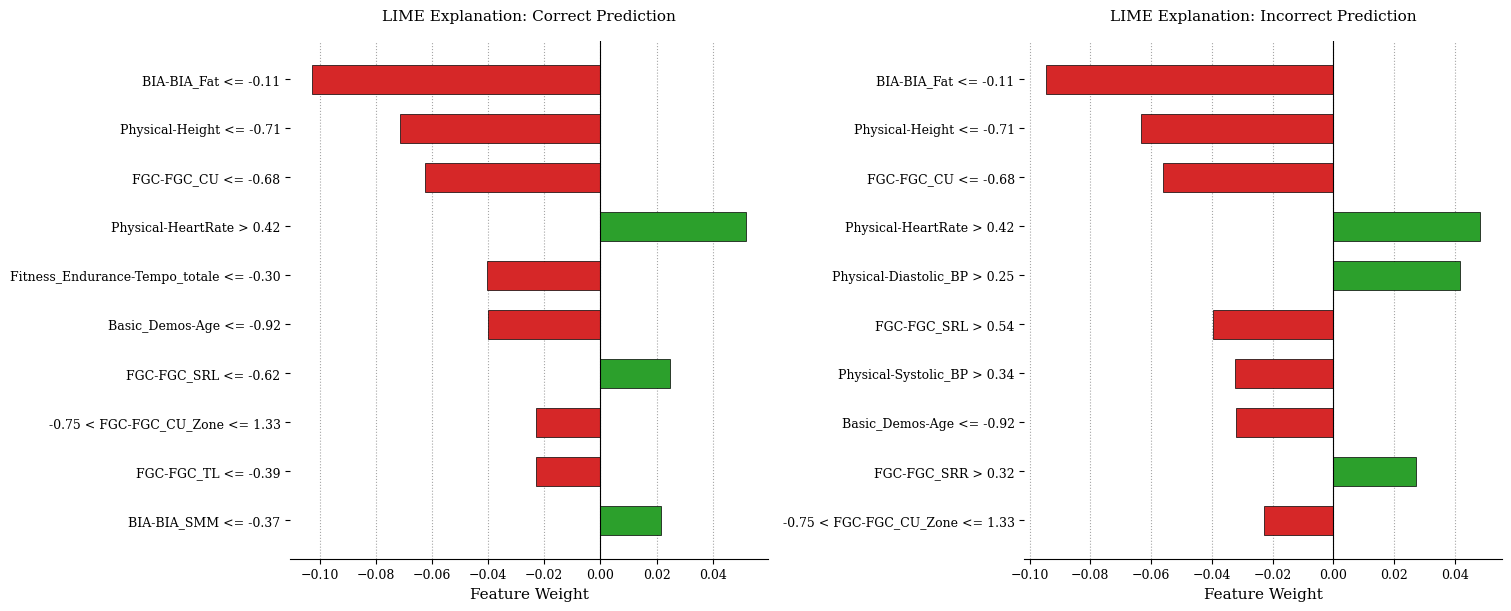

In [26]:
plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 11,
    'axes.titlesize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9
})

# Feature names extraction
feature_names = X.columns.tolist()
class_names_list = [str(c) for c in np.unique(y_train)]

# LIME explainer initialization
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_scaled,
    feature_names=feature_names,
    class_names=class_names_list,
    mode='classification',
    random_state=222
)

# Wrapper function for model predictions


def predict_fn(x):
    return best_L2_model.predict(x, verbose=0)


# Explanation for correct observation
exp_lime_correct = explainer_lime.explain_instance(
    data_row=obs_correct,
    predict_fn=predict_fn,
    num_features=10
)

# Explanation for incorrect observation
exp_lime_incorrect = explainer_lime.explain_instance(
    data_row=obs_incorrect,
    predict_fn=predict_fn,
    num_features=10
)

# ==========================================
# Academic Plotting Function for LIME
# ==========================================


def plot_lime_explanation(exp, title, ax):
    # Extract feature conditions and their corresponding weights
    exp_list = exp.as_list()
    features = [x[0] for x in exp_list]
    weights = [x[1] for x in exp_list]

    # Colors: Green for positive impact, Red for negative impact
    colors = ['#2ca02c' if w > 0 else '#d62728' for w in weights]

    y_pos = range(len(features))
    ax.barh(y_pos, weights, color=colors,
            edgecolor='black', linewidth=0.5, height=0.6)

    ax.set_yticks(y_pos)
    ax.set_yticklabels(features)
    ax.invert_yaxis()  # Display highest impact features at the top

    # Spines and grid formatting
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.xaxis.grid(True, linestyle=':', alpha=0.7, color='gray')
    ax.set_axisbelow(True)

    # Add vertical zero-line for clear reference
    ax.axvline(0, color='black', linewidth=0.8)

    ax.set_title(title, pad=15)
    ax.set_xlabel("Feature Weight")


# Generate side-by-side figure
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

plot_lime_explanation(
    exp_lime_correct, "LIME Explanation: Correct Prediction", axes[0])
plot_lime_explanation(exp_lime_incorrect,
                      "LIME Explanation: Incorrect Prediction", axes[1])

plt.show()

In [27]:
np.random.seed(222)
background_data = shap.kmeans(X_train_scaled, 100)

# 2. Definizione della funzione di predizione
# best_L2_model restituisce un array di probabilità (n_istanze, 4_classi)


def predict_fn(x): return best_L2_model.predict(x, verbose=0)


# 3. Inizializzazione dell'explainer
explainer_shap_global = shap.KernelExplainer(predict_fn, background_data)

# 4. Campionamento del Test Set
# Selezioniamo 100 istanze casuali per valutare il comportamento globale in tempi ragionevoli
sample_size = 100
np.random.seed(222)
indices_global = np.random.choice(
    X_test_scaled.shape[0], sample_size, replace=False)
X_test_sample = X_test_scaled[indices_global]

# 5. Calcolo dei valori SHAP
print(
    f"Calcolo dei valori SHAP per {sample_size} istanze (potrebbe richiedere qualche minuto)...")
shap_values_global = explainer_shap_global.shap_values(X_test_sample)


# plt.show()

Calcolo dei valori SHAP per 100 istanze (potrebbe richiedere qualche minuto)...


  0%|          | 0/100 [00:00<?, ?it/s]

C:\Users\Riccardo\AppData\Local\Temp\ipykernel_19796\1018630537.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


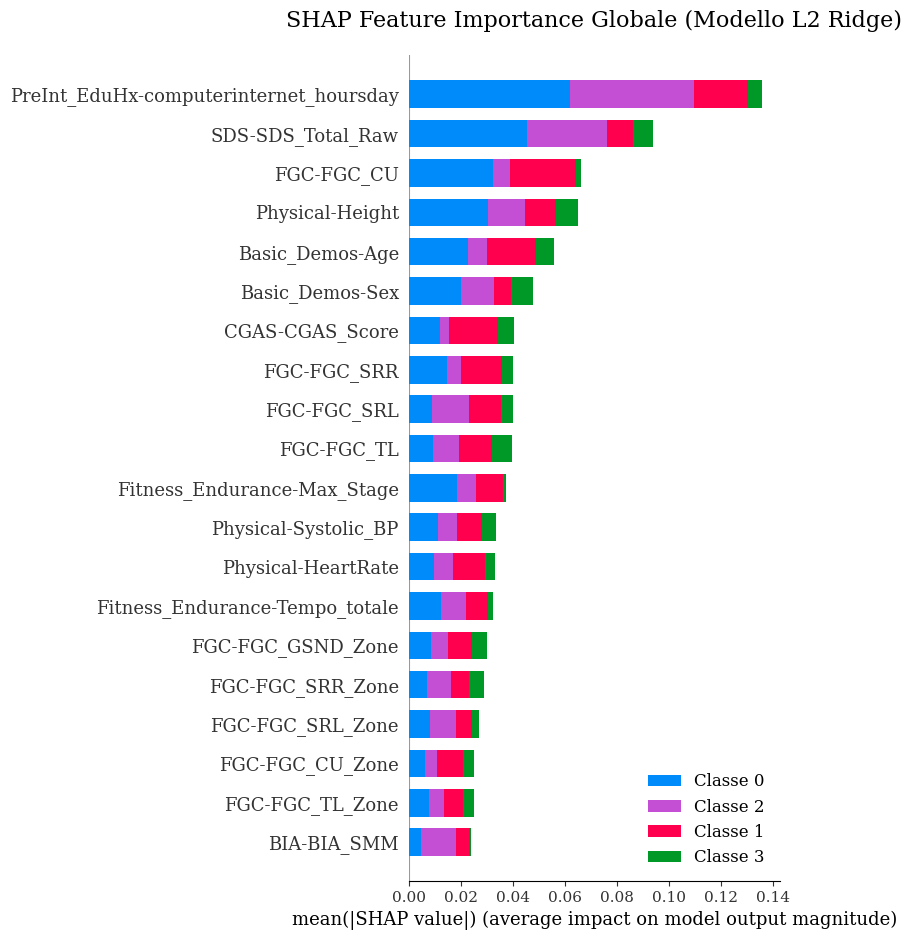

C:\Users\Riccardo\AppData\Local\Temp\ipykernel_19796\1018630537.py:59: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


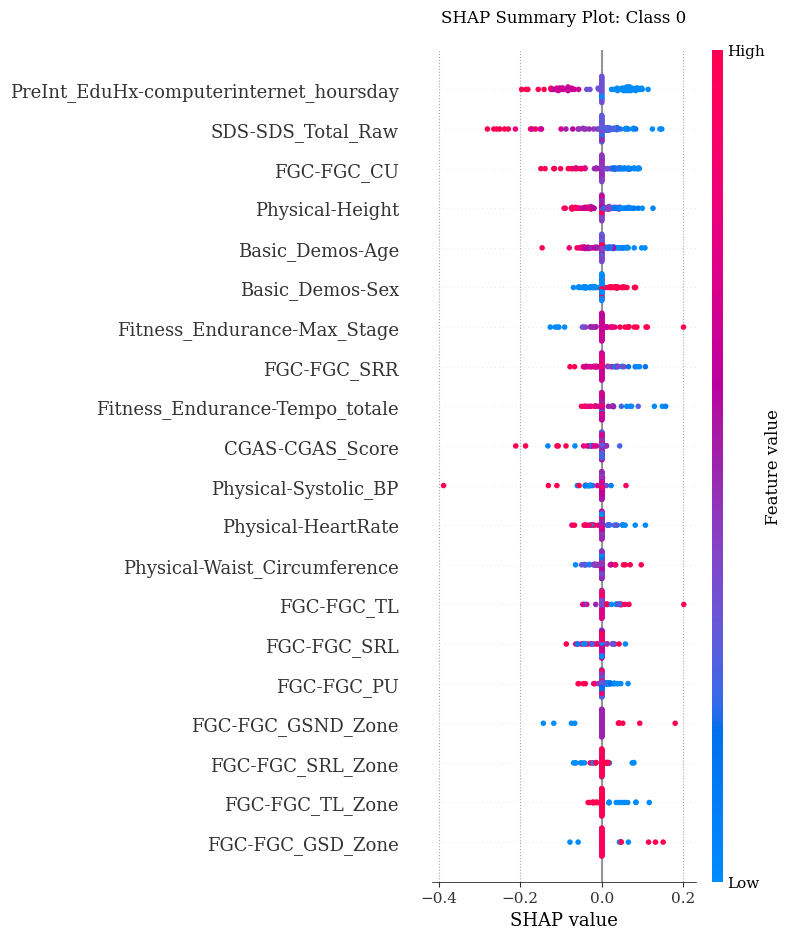

In [ ]:
# GRAFICI SHAP GLOBALE

# 6. Generazione del Summary Plot Globale (Bar Chart Impilato)
# Essendo multiclasse, passiamo l'intera lista di valori SHAP per vedere l'impatto di
# ogni feature aggregato per tutte le classi.
plt.figure(figsize=(12, 8))
plt.title("SHAP Feature Importance Globale (Modello L2 Ridge)",
          fontsize=16, pad=20)
shap.summary_plot(
    shap_values_global,
    X_test_sample,
    feature_names=feature_names,
    plot_type="bar",
    class_names=["Classe 0", "Classe 1", "Classe 2",
                 "Classe 3"],  # Sostituisci se hai label testuali
    show=False  # Permette di formattare il grafico prima di mostrarlo
)
plt.tight_layout()
plt.show()

###########

plt.rcParams.update({
    'font.family': 'serif',
    'axes.labelsize': 11,
    'axes.titlesize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9
})

# Target class selection (0, 1, 2, or 3)
target_class = 0

# 1. Safe extraction of SHAP values for the target class
if isinstance(shap_values_global, list):
    # Legacy format: list of 2D arrays
    shap_values_target = shap_values_global[target_class]

elif isinstance(shap_values_global, np.ndarray):
    # Array format: check axis layout (samples, classes, features) or (samples, features, classes)
    if shap_values_global.ndim == 3:
        # Assuming 4 classes
        if shap_values_global.shape[1] == 4:
            shap_values_target = shap_values_global[:, target_class, :]
        else:
            shap_values_target = shap_values_global[:, :, target_class]
    else:
        shap_values_target = shap_values_global

else:
    # Explanation object format (new SHAP API)
    shap_values_target = shap_values_global[:, :, target_class].values

# 2. Plot generation
# Incrementata la larghezza della figura (da 10 a 12)
fig = plt.figure(figsize=(12, 8))

# Generate SHAP summary plot (Beeswarm)
shap.summary_plot(
    shap_values_target,
    X_test_sample,
    feature_names=feature_names,
    show=False
)

# Academic formatting adjustments after SHAP plotting
ax = plt.gca()
ax.set_title(f"SHAP Summary Plot: Class {target_class}", fontsize=12, pad=20)

# Sovrascrittura dell'etichetta dell'asse X
ax.set_xlabel("SHAP value")

# Ensure unnecessary spines are hidden (SHAP sometimes overrides rcParams)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_linewidth(0.5)

# Optional: Add a subtle grid for the x-axis to improve readability of SHAP values
ax.xaxis.grid(True, linestyle=':', alpha=0.7, color='gray')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## Logistica
---

In [8]:
# Logistica

# Inizializzazione del modello base
logistica_base = LogisticRegression(
    random_state=222,
    class_weight='balanced',
    multi_class='multinomial',
    max_iter=1000,
    solver='lbfgs',  # algoritmo specializzato per l2; prima usavo saga
    penalty='l2',  # facendo delle prove, l2 è meglio di l1
    tol=1e-3
)

# Iperparametri
parametri_log = {
    # regolarizzazione della logistica
    'C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
}

# Grid Search
gs_logistica = GridSearchCV(
    estimator=logistica_base,
    param_grid=parametri_log,
    scoring='f1_macro',
    cv=10,
    verbose=1,
    n_jobs=1
)

# Training
gs_logistica.fit(X_train_scaled, y_train)

# Risultati
best_logistica = gs_logistica.best_estimator_

print("### CONFIGURAZIONE OTTIMALE LOGISTICA ###")
for parametro, valore in gs_logistica.best_params_.items():
    print(f" - {parametro}: {valore}")

print("\n### REPORT DI CLASSIFICAZIONE (TEST SET) ###")
y_pred_log = best_logistica.predict(X_test_scaled)
print(classification_report(y_test, y_pred_log))


print("### METRICHE PER TABELLA LATEX ###\n")

# 1. CV F1-macro: il miglior punteggio medio ottenuto durante la Cross-Validation
cv_f1_macro = gs_logistica.best_score_
print(f"CV F1-macro   : {cv_f1_macro:.4f}")

# 2. Test Accuracy: l'accuratezza globale calcolata sulle previsioni del Test Set
test_accuracy = accuracy_score(y_test, y_pred_log)
print(f"Test Accuracy : {test_accuracy:.4f}")

# 3. Test F1-macro: la media macro degli F1-score calcolata sul Test Set
test_f1_macro = f1_score(y_test, y_pred_log, average='macro')
print(f"Test F1-macro : {test_f1_macro:.4f}")

print("\n### RIGA LATEX PRONTA ###")
# Genera direttamente la stringa da copiare e incollare nella tabella
riga_latex = f"Logistic Regression & {cv_f1_macro:.4f} & {test_accuracy:.4f} & {test_f1_macro:.4f} \\\\"
print(riga_latex)

Fitting 10 folds for each of 7 candidates, totalling 70 fits


c:\Users\Riccardo\anaconda3\envs\tf-directml\lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\Riccardo\anaconda3\envs\tf-directml\lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\Riccardo\anaconda3\envs\tf-directml\lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\Riccardo\anaconda3\envs\tf-directml\lib\site-packages\sklearn\linea

### CONFIGURAZIONE OTTIMALE LOGISTICA ###
 - C: 0.01

### REPORT DI CLASSIFICAZIONE (TEST SET) ###
              precision    recall  f1-score   support

           0       0.83      0.59      0.69      1689
           1       0.30      0.23      0.26       469
           2       0.25      0.37      0.30       284
           3       0.02      0.42      0.04        26

    accuracy                           0.49      2468
   macro avg       0.35      0.40      0.32      2468
weighted avg       0.65      0.49      0.56      2468

### METRICHE PER TABELLA LATEX ###

CV F1-macro   : 0.3016
Test Accuracy : 0.4935
Test F1-macro : 0.3228

### RIGA LATEX PRONTA ###
Logistic Regression & 0.3016 & 0.4935 & 0.3228 \\


c:\Users\Riccardo\anaconda3\envs\tf-directml\lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\Riccardo\anaconda3\envs\tf-directml\lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
